In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls /content/drive/MyDrive

 archive  'Colab Notebooks'


In [ ]:
!ls /content/drive/MyDrive/archive

EuroSAT  EuroSATallBands


In [ ]:
!cp -r /content/drive/MyDrive/archive/EuroSAT /content/

In [ ]:
dataset_path = "/content/EuroSAT"
full_dataset = ImageFolder(root=dataset_path, transform=transform)

print("Total samples:", len(full_dataset))
print("Classes:", full_dataset.classes)

Total samples: 27000
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [ ]:
temp_transform = transforms.ToTensor()
temp_dataset = ImageFolder(root=dataset_path, transform=temp_transform)
temp_loader = DataLoader(temp_dataset, batch_size=64, shuffle=False)

mean = 0.
std = 0.
total_images = 0

for images, _ in temp_loader:
    batch_samples = images.size(0)
    images = images.view(batch_samples, images.size(1), -1)
    mean += images.mean(2).sum(0)
    std += images.std(2).sum(0)
    total_images += batch_samples

mean /= total_images
std /= total_images

print("Mean:", mean)
print("Std:", std)

Mean: tensor([0.3444, 0.3803, 0.4078])
Std: tensor([0.0914, 0.0651, 0.0552])


In [ ]:
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean.tolist(), std=std.tolist())
])

In [ ]:
full_dataset = ImageFolder(root=dataset_path, transform=transform)

train_size = int(0.7 * len(full_dataset))
test_size = len(full_dataset) - train_size

train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])

batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [ ]:
class TwoLayerNet(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(TwoLayerNet, self).__init__()

        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def sigmoid(self, x):
        return 1 / (1 + torch.exp(-x))

    def softmax(self, x):
        # Numerical stability
        x = x - torch.max(x, dim=1, keepdim=True)[0]
        exp_x = torch.exp(x)
        return exp_x / torch.sum(exp_x, dim=1, keepdim=True)

    def forward(self, x):
        # Flatten
        x = x.view(x.size(0), -1)

        z1 = self.fc1(x)
        a1 = self.sigmoid(z1)

        z2 = self.fc2(a1)
        output = self.softmax(z2)

        return output

In [ ]:
input_dim = 64 * 64 * 3
hidden_dim = 256
output_dim = 10

model = TwoLayerNet(input_dim, hidden_dim, output_dim).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()

In [ ]:
def forward(self, x):
    x = x.view(x.size(0), -1)

    z1 = self.fc1(x)
    a1 = self.sigmoid(z1)

    logits = self.fc2(a1)

    return logits

In [ ]:
learning_rate = 0.0001
epochs = 5

In [ ]:
train_losses = []
test_accuracies = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        for param in model.parameters():
            param.grad = None

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()

        with torch.no_grad():
            for param in model.parameters():
                param -= learning_rate * param.grad

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    accuracy = 100 * correct / total
    test_accuracies.append(accuracy)

    print(f"Epoch [{epoch+1}/{epochs}] Loss: {avg_loss:.4f} Test Accuracy: {accuracy:.2f}%")

Epoch [1/5] Loss: 2.2992 Test Accuracy: 14.54%
Epoch [2/5] Loss: 2.2933 Test Accuracy: 15.14%
Epoch [3/5] Loss: 2.2872 Test Accuracy: 16.59%
Epoch [4/5] Loss: 2.2807 Test Accuracy: 17.42%
Epoch [5/5] Loss: 2.2744 Test Accuracy: 17.81%


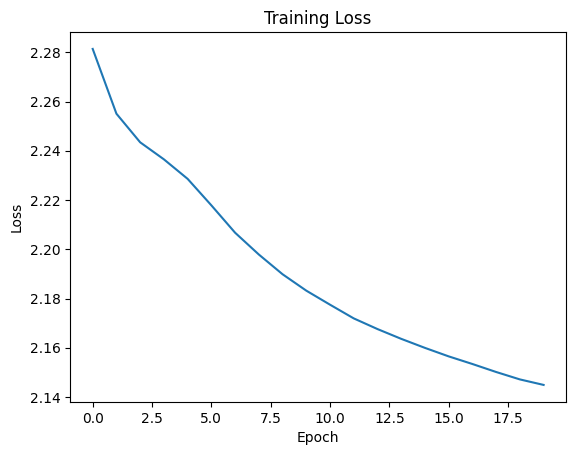

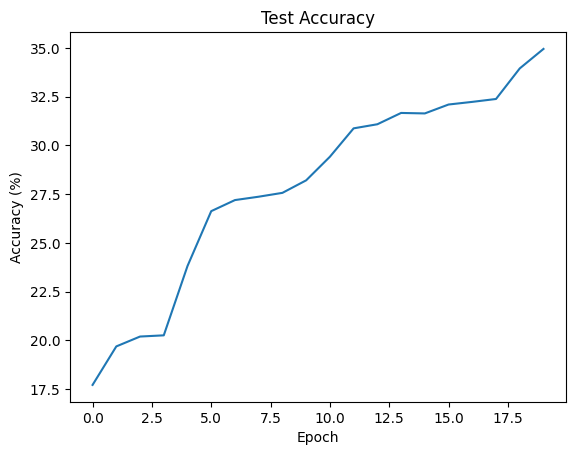

In [ ]:
plt.plot(train_losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

plt.plot(test_accuracies)
plt.title("Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.show()

In [ ]:
#Designing the Baseline Producer

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Sigmoid from scratch
def sigmoid(x):
    return 1 / (1 + torch.exp(-x))

# Softmax from scratch
def softmax(x):
    exp_x = torch.exp(x - torch.max(x))  # stability
    return exp_x / torch.sum(exp_x, dim=1, keepdim=True)

In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()

        # -------- Convolution Layers --------
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        # -------- Fully Connected Layers --------
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        # Conv Block 1
        x = self.conv1(x)
        x = sigmoid(x)

        # Conv Block 2
        x = self.conv2(x)
        x = sigmoid(x)
        x = self.pool(x)

        # Conv Block 3
        x = self.conv3(x)
        x = sigmoid(x)
        x = self.pool(x)

        # Flatten
        x = x.view(x.size(0), -1)

        # Fully Connected
        x = self.fc1(x)
        x = sigmoid(x)

        x = self.fc2(x)
        x = softmax(x)

        return x

In [ ]:
def cross_entropy_loss(predictions, labels):
    return -torch.sum(labels * torch.log(predictions + 1e-8))

In [ ]:
def one_hot(labels, num_classes=10):
    return F.one_hot(labels, num_classes).float()

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BaselineCNN().to(device)

learning_rate = 0.01
epochs = 20

In [ ]:
for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Batch size must be 1
        # Make sure DataLoader batch_size=1

        # ---- Reset gradients manually ----
        for param in model.parameters():
            param.grad = None

        # ---- Forward pass ----
        outputs = model(images)

        # Convert labels to one-hot
        labels_one_hot = one_hot(labels)

        # ---- Compute loss ----
        loss = cross_entropy_loss(outputs, labels_one_hot)

        # ---- Backward pass ----
        loss.backward()

        # ---- Manual SGD update ----
        with torch.no_grad():
            for param in model.parameters():
                param -= learning_rate * param.grad

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss}")

Epoch 1, Loss: 46101.37952041626
Epoch 2, Loss: 44157.36698913574
Epoch 3, Loss: 44076.666358947754
Epoch 4, Loss: 44040.34513092041
Epoch 5, Loss: 40700.05061721802
Epoch 6, Loss: nan
Epoch 7, Loss: nan
Epoch 8, Loss: nan
Epoch 9, Loss: nan
Epoch 10, Loss: nan
Epoch 11, Loss: nan
Epoch 12, Loss: nan
Epoch 13, Loss: nan
Epoch 14, Loss: nan
Epoch 15, Loss: nan
Epoch 16, Loss: nan
Epoch 17, Loss: nan
Epoch 18, Loss: nan
Epoch 19, Loss: nan
Epoch 20, Loss: nan


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predicted = torch.argmax(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print("Test Accuracy:", accuracy)

Test Accuracy: 10.901234567901234


In [ ]:
#Part - 2: Experimenting with different activation functions

In [ ]:
def cross_entropy_loss(logits, labels):
    """
    logits: (batch, 10)
    labels: (batch,)  -> class indices
    """

    # Log-Softmax (stable)
    log_probs = logits - torch.log(torch.sum(torch.exp(logits), dim=1, keepdim=True))

    # Pick correct class log prob
    loss = -log_probs[range(len(labels)), labels]

    return loss.mean()

In [ ]:
def leaky_relu(x):
    return torch.maximum(x, 0.1 * x)

In [ ]:
def silu(x):
    return x / (1 + torch.exp(-x))

In [ ]:
class CNN_LeakyReLU(nn.Module):
    def __init__(self):
        super(CNN_LeakyReLU, self).__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = leaky_relu(self.conv1(x))

        x = leaky_relu(self.conv2(x))
        x = self.pool(x)

        x = leaky_relu(self.conv3(x))
        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = leaky_relu(self.fc1(x))

        x = self.fc2(x)   # NO softmax

        return x

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CNN_SiLU(nn.Module):
    def __init__(self):
        super(CNN_SiLU, self).__init__()

        # Convolution Layers
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        # Activation
        self.act = nn.SiLU()

        # Fully Connected Layers
        # Assumes input image is 64x64
        # After 2 pooling layers → 16x16 feature map
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        # Conv Block 1
        x = self.act(self.conv1(x))

        # Conv Block 2
        x = self.act(self.conv2(x))
        x = self.pool(x)

        # Conv Block 3
        x = self.act(self.conv3(x))
        x = self.pool(x)

        # Flatten
        x = x.view(x.size(0), -1)

        # Fully Connected
        x = self.act(self.fc1(x))
        x = self.fc2(x)   # IMPORTANT: No softmax here

        return x

In [ ]:
learning_rate = 0.001
epochs = 20

model = CNN_LeakyReLU().to(device)
# OR
# model = CNN_SiLU().to(device)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        for param in model.parameters():
            param.grad = None

        # Forward
        outputs = model(images)

        # Loss (stable version)
        loss = cross_entropy_loss(outputs, labels)

        # Backward
        loss.backward()

        # Manual SGD
        with torch.no_grad():
            for param in model.parameters():
                param -= learning_rate * param.grad

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")

Epoch 1, Loss: 2.1077
Epoch 2, Loss: 1.8534
Epoch 3, Loss: 1.7475
Epoch 4, Loss: 1.6556
Epoch 5, Loss: 1.5556
Epoch 6, Loss: 1.4518
Epoch 7, Loss: 1.3529
Epoch 8, Loss: 1.2645
Epoch 9, Loss: 1.1777
Epoch 10, Loss: 1.1082
Epoch 11, Loss: 1.0513
Epoch 12, Loss: 1.0056
Epoch 13, Loss: 0.9687
Epoch 14, Loss: 0.9317
Epoch 15, Loss: 0.9000
Epoch 16, Loss: 0.8816
Epoch 17, Loss: 0.8547
Epoch 18, Loss: 0.8397
Epoch 19, Loss: 0.8148
Epoch 20, Loss: 0.7941


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print("Test Accuracy:", 100 * correct / total)

Test Accuracy: 64.19753086419753


In [ ]:
learning_rate = 0.001
epochs = 20

#model = CNN_LeakyReLU().to(device)
# OR
model = CNN_SiLU().to(device)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        for param in model.parameters():
            param.grad = None

        # Forward
        outputs = model(images)

        # Loss (stable version)
        loss = cross_entropy_loss(outputs, labels)

        # Backward
        loss.backward()

        # Manual SGD
        with torch.no_grad():
            for param in model.parameters():
                param -= learning_rate * param.grad

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")

Epoch 1, Loss: 2.2287
Epoch 2, Loss: 2.0351
Epoch 3, Loss: 1.8679
Epoch 4, Loss: 1.7569
Epoch 5, Loss: 1.6675
Epoch 6, Loss: 1.5839
Epoch 7, Loss: 1.5187
Epoch 8, Loss: 1.4679
Epoch 9, Loss: 1.4218
Epoch 10, Loss: 1.3799
Epoch 11, Loss: 1.3385
Epoch 12, Loss: 1.2890
Epoch 13, Loss: 1.2412
Epoch 14, Loss: 1.1943
Epoch 15, Loss: 1.1489
Epoch 16, Loss: 1.1150
Epoch 17, Loss: 1.0835
Epoch 18, Loss: 1.0567
Epoch 19, Loss: 1.0308
Epoch 20, Loss: 1.0067


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print("Test Accuracy:", 100 * correct / total)

Test Accuracy: 64.88888888888889


In [ ]:
# Optimisers and momentum and different batch sizes

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

model = CNN_LeakyReLU().to(device)
# OR
# model = CNN_SiLU().to(device)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        for param in model.parameters():
            param.grad = None

        # Forward pass
        outputs = model(images)

        # Average batch loss
        loss = cross_entropy_loss(outputs, labels)  # Make sure this returns mean loss

        # Backward pass
        loss.backward()

        # Mini-batch SGD update
        with torch.no_grad():
            for param in model.parameters():
                param -= learning_rate * param.grad

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

Epoch 1, Loss: 1.7937
Epoch 2, Loss: 1.3607
Epoch 3, Loss: 1.1266
Epoch 4, Loss: 0.9802
Epoch 5, Loss: 0.8878
Epoch 6, Loss: 0.8200
Epoch 7, Loss: 0.7723
Epoch 8, Loss: 0.7326
Epoch 9, Loss: 0.7014
Epoch 10, Loss: 0.6789
Epoch 11, Loss: 0.6553
Epoch 12, Loss: 0.6409
Epoch 13, Loss: 0.6222
Epoch 14, Loss: 0.6114
Epoch 15, Loss: 0.5987
Epoch 16, Loss: 0.5916
Epoch 17, Loss: 0.5780
Epoch 18, Loss: 0.5665
Epoch 19, Loss: 0.5615
Epoch 20, Loss: 0.5551


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print("Test Accuracy:", 100 * correct / total)

Test Accuracy: 79.37037037037037


In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

#model = CNN_LeakyReLU().to(device)
# OR
model = CNN_SiLU().to(device)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        for param in model.parameters():
            param.grad = None

        # Forward pass
        outputs = model(images)

        # Average batch loss
        loss = cross_entropy_loss(outputs, labels)  # Make sure this returns mean loss

        # Backward pass
        loss.backward()

        # Mini-batch SGD update
        with torch.no_grad():
            for param in model.parameters():
                param -= learning_rate * param.grad

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

Epoch 1, Loss: 2.0472
Epoch 2, Loss: 1.6310
Epoch 3, Loss: 1.3945
Epoch 4, Loss: 1.2052
Epoch 5, Loss: 1.0727
Epoch 6, Loss: 0.9678
Epoch 7, Loss: 0.8809
Epoch 8, Loss: 0.8169
Epoch 9, Loss: 0.7671
Epoch 10, Loss: 0.7258
Epoch 11, Loss: 0.6967
Epoch 12, Loss: 0.6682
Epoch 13, Loss: 0.6397
Epoch 14, Loss: 0.6278
Epoch 15, Loss: 0.6088
Epoch 16, Loss: 0.5970
Epoch 17, Loss: 0.5755
Epoch 18, Loss: 0.5674
Epoch 19, Loss: 0.5511
Epoch 20, Loss: 0.5406


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print("Test Accuracy:", 100 * correct / total)

Test Accuracy: 78.85185185185185


In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16
alpha = 0.9   # momentum strength

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

model = CNN_LeakyReLU().to(device)

# Initialize momentum buffers
momentum_buffer = {}
for name, param in model.named_parameters():
    momentum_buffer[name] = torch.zeros_like(param)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        for param in model.parameters():
            param.grad = None

        # Forward
        outputs = model(images)

        loss = cross_entropy_loss(outputs, labels)

        # Backward
        loss.backward()

        # Mini-batch SGD + Momentum update
        with torch.no_grad():
            for name, param in model.named_parameters():

                g = param.grad

                # Update momentum
                momentum_buffer[name] = alpha * momentum_buffer[name] + g

                # Update parameters
                param -= learning_rate * momentum_buffer[name]

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

Epoch 1, Loss: 1.2902
Epoch 2, Loss: 0.8323
Epoch 3, Loss: 0.6990
Epoch 4, Loss: 0.6147
Epoch 5, Loss: 0.5600
Epoch 6, Loss: 0.5183
Epoch 7, Loss: 0.4705
Epoch 8, Loss: 0.4451
Epoch 9, Loss: 0.4172
Epoch 10, Loss: 0.3902
Epoch 11, Loss: 0.3668
Epoch 12, Loss: 0.3527
Epoch 13, Loss: 0.3403
Epoch 14, Loss: 0.3420
Epoch 15, Loss: 0.3091
Epoch 16, Loss: 0.3049
Epoch 17, Loss: 0.2880
Epoch 18, Loss: 0.2818
Epoch 19, Loss: 0.2710
Epoch 20, Loss: 0.2587


In [ ]:
# ----------------- TEST ACCURACY -----------------
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

model.train()  # switch back to training mode

Test Accuracy: 89.33%


CNN_LeakyReLU(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16
alpha = 0.9

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

model = CNN_SiLU().to(device)

# Momentum buffer
momentum_buffer = {}
for name, param in model.named_parameters():
    momentum_buffer[name] = torch.zeros_like(param)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        for param in model.parameters():
            param.grad = None

        # Forward
        outputs = model(images)

        loss = cross_entropy_loss(outputs, labels)

        # Backward
        loss.backward()

        # SGD + Momentum
        with torch.no_grad():
            for name, param in model.named_parameters():

                g = param.grad
                momentum_buffer[name] = alpha * momentum_buffer[name] + g
                param -= learning_rate * momentum_buffer[name]

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    # ----------------- TEST ACCURACY -----------------
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Test Accuracy: {test_accuracy:.2f}%")


Epoch [1/20] Loss: 1.4315 Test Accuracy: 64.47%
Epoch [2/20] Loss: 0.8484 Test Accuracy: 73.46%
Epoch [3/20] Loss: 0.7056 Test Accuracy: 76.53%
Epoch [4/20] Loss: 0.6252 Test Accuracy: 79.69%
Epoch [5/20] Loss: 0.5760 Test Accuracy: 78.90%
Epoch [6/20] Loss: 0.5391 Test Accuracy: 80.41%
Epoch [7/20] Loss: 0.4895 Test Accuracy: 81.51%
Epoch [8/20] Loss: 0.4607 Test Accuracy: 82.84%
Epoch [9/20] Loss: 0.4316 Test Accuracy: 85.44%
Epoch [10/20] Loss: 0.4023 Test Accuracy: 85.68%
Epoch [11/20] Loss: 0.3915 Test Accuracy: 85.74%
Epoch [12/20] Loss: 0.3692 Test Accuracy: 85.20%
Epoch [13/20] Loss: 0.3414 Test Accuracy: 87.57%
Epoch [14/20] Loss: 0.3244 Test Accuracy: 86.85%
Epoch [15/20] Loss: 0.3040 Test Accuracy: 87.11%
Epoch [16/20] Loss: 0.2991 Test Accuracy: 88.40%
Epoch [17/20] Loss: 0.2808 Test Accuracy: 88.36%
Epoch [18/20] Loss: 0.2719 Test Accuracy: 89.70%
Epoch [19/20] Loss: 0.2607 Test Accuracy: 89.57%
Epoch [20/20] Loss: 0.2507 Test Accuracy: 87.46%


In [ ]:
class CNN_LeakyReLU_Deep(nn.Module):
    def __init__(self):
        super(CNN_LeakyReLU_Deep, self).__init__()

        self.act = nn.LeakyReLU(0.1)

        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2,2)

        # ---- 10 EXTRA CONV LAYERS ----
        self.extra_layers = nn.Sequential(
            *[nn.Sequential(
                nn.Conv2d(64, 64, 3, padding=1),
                nn.LeakyReLU(0.1)
            ) for _ in range(10)]
        )

        self.fc1 = nn.Linear(64*16*16, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.act(self.conv1(x))

        x = self.act(self.conv2(x))
        x = self.pool(x)

        x = self.act(self.conv3(x))
        x = self.pool(x)

        # Extra deep layers (no skip)
        x = self.extra_layers(x)

        x = x.view(x.size(0), -1)

        x = self.act(self.fc1(x))
        x = self.fc2(x)

        return x

In [ ]:
class CNN_SiLU_Deep(nn.Module):
    def __init__(self):
        super(CNN_SiLU_Deep, self).__init__()

        self.act = nn.SiLU()

        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2,2)

        # ---- 10 EXTRA CONV LAYERS ----
        self.extra_layers = nn.Sequential(
            *[nn.Sequential(
                nn.Conv2d(64, 64, 3, padding=1),
                nn.SiLU()
            ) for _ in range(10)]
        )

        self.fc1 = nn.Linear(64*16*16, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.act(self.conv1(x))

        x = self.act(self.conv2(x))
        x = self.pool(x)

        x = self.act(self.conv3(x))
        x = self.pool(x)

        # Extra deep layers (no skip)
        x = self.extra_layers(x)

        x = x.view(x.size(0), -1)

        x = self.act(self.fc1(x))
        x = self.fc2(x)

        return x

In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16
alpha = 0.9

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

model = CNN_LeakyReLU_Deep().to(device)

# Momentum buffer
momentum_buffer = {}
for name, param in model.named_parameters():
    momentum_buffer[name] = torch.zeros_like(param)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        for param in model.parameters():
            param.grad = None

        # Forward
        outputs = model(images)

        loss = cross_entropy_loss(outputs, labels)

        # Backward
        loss.backward()

        # SGD + Momentum
        with torch.no_grad():
            for name, param in model.named_parameters():

                g = param.grad
                momentum_buffer[name] = alpha * momentum_buffer[name] + g
                param -= learning_rate * momentum_buffer[name]

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    # ----------------- TEST ACCURACY -----------------
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Test Accuracy: {test_accuracy:.2f}%")


Epoch [1/20] Loss: 2.2977 Test Accuracy: 10.90%
Epoch [2/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [3/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [4/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [5/20] Loss: 2.2957 Test Accuracy: 10.63%
Epoch [6/20] Loss: 2.2957 Test Accuracy: 10.63%
Epoch [7/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [8/20] Loss: 2.2955 Test Accuracy: 11.47%
Epoch [9/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [10/20] Loss: 2.2956 Test Accuracy: 10.90%
Epoch [11/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [12/20] Loss: 2.2955 Test Accuracy: 10.90%
Epoch [13/20] Loss: 2.2955 Test Accuracy: 10.90%
Epoch [14/20] Loss: 2.2955 Test Accuracy: 10.90%
Epoch [15/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [16/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [17/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [18/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [19/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [20/20] Loss: 2.2955 Test Accuracy: 10.63%


In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16
alpha = 0.9

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# -------- CHOOSE MODEL HERE --------
# model = CNN_LeakyReLU_Deep().to(device)
model = CNN_SiLU_Deep().to(device)

# -------- Momentum Buffer --------
momentum_buffer = {}
for name, param in model.named_parameters():
    momentum_buffer[name] = torch.zeros_like(param)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    total_grad_norm = 0
    grad_count = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        for param in model.parameters():
            param.grad = None

        # Forward
        outputs = model(images)

        loss = cross_entropy_loss(outputs, labels)

        # Backward
        loss.backward()

        # ---- Record Gradient Norm (First Epoch Only) ----
        if epoch == 0:
            for param in model.parameters():
                if param.grad is not None:
                    total_grad_norm += param.grad.abs().sum().item()
                    grad_count += 1

        # ---- Mini-batch SGD + Momentum ----
        with torch.no_grad():
            for name, param in model.named_parameters():
                g = param.grad
                momentum_buffer[name] = alpha * momentum_buffer[name] + g
                param -= learning_rate * momentum_buffer[name]

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    # Print Gradient Norm
    if epoch == 0:
        avg_grad_norm = total_grad_norm / grad_count
        print("Average L1 Gradient (Epoch 1):", avg_grad_norm)

    # -------- TESTING --------
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Test Accuracy: {test_accuracy:.2f}%")


Average L1 Gradient (Epoch 1): 4.144067150258413
Epoch [1/20] Loss: 2.2982 Test Accuracy: 10.90%
Epoch [2/20] Loss: 2.2957 Test Accuracy: 10.63%
Epoch [3/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [4/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [5/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [6/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [7/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [8/20] Loss: 2.2957 Test Accuracy: 10.63%
Epoch [9/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [10/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [11/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [12/20] Loss: 2.2955 Test Accuracy: 10.90%
Epoch [13/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [14/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [15/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [16/20] Loss: 2.2955 Test Accuracy: 10.90%
Epoch [17/20] Loss: 2.2954 Test Accuracy: 10.63%
Epoch [18/20] Loss: 2.2954 Test Accuracy: 10.63%
Epoch [19/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [20/20] Loss: 2.2955 Te

In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16
alpha = 0.9

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# -------- CHOOSE MODEL HERE --------
model = CNN_LeakyReLU_Deep().to(device)
#model = CNN_SiLU_Deep().to(device)

# -------- Momentum Buffer --------
momentum_buffer = {}
for name, param in model.named_parameters():
    momentum_buffer[name] = torch.zeros_like(param)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    total_grad_norm = 0
    grad_count = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        for param in model.parameters():
            param.grad = None

        # Forward
        outputs = model(images)

        loss = cross_entropy_loss(outputs, labels)

        # Backward
        loss.backward()

        # ---- Record Gradient Norm (First Epoch Only) ----
        if epoch == 0:
            for param in model.parameters():
                if param.grad is not None:
                    total_grad_norm += param.grad.abs().sum().item()
                    grad_count += 1

        # ---- Mini-batch SGD + Momentum ----
        with torch.no_grad():
            for name, param in model.named_parameters():
                g = param.grad
                momentum_buffer[name] = alpha * momentum_buffer[name] + g
                param -= learning_rate * momentum_buffer[name]

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    # Print Gradient Norm
    if epoch == 0:
        avg_grad_norm = total_grad_norm / grad_count
        print("Average L1 Gradient (Epoch 1):", avg_grad_norm)

    # -------- TESTING --------
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Test Accuracy: {test_accuracy:.2f}%")


Average L1 Gradient (Epoch 1): 3.590694196755351
Epoch [1/20] Loss: 2.2981 Test Accuracy: 10.63%
Epoch [2/20] Loss: 2.2957 Test Accuracy: 10.63%
Epoch [3/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [4/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [5/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [6/20] Loss: 2.2956 Test Accuracy: 10.90%
Epoch [7/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [8/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [9/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [10/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [11/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [12/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [13/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [14/20] Loss: 2.2957 Test Accuracy: 10.90%
Epoch [15/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [16/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [17/20] Loss: 2.2955 Test Accuracy: 10.63%
Epoch [18/20] Loss: 2.2955 Test Accuracy: 10.90%
Epoch [19/20] Loss: 2.2956 Test Accuracy: 10.63%
Epoch [20/20] Loss: 2.2956 Te

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CNN_LeakyReLU_Skip(nn.Module):
    def __init__(self):
        super(CNN_LeakyReLU_Skip, self).__init__()

        self.act = nn.LeakyReLU(0.1)

        # Initial Conv Layers
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2,2)

        # 5 Residual Blocks = 10 Layers
        self.res_blocks = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(64, 64, 3, padding=1),
                nn.LeakyReLU(0.1),
                nn.Conv2d(64, 64, 3, padding=1)
            )
            for _ in range(5)
        ])

        self.fc1 = nn.Linear(64*16*16, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.act(self.conv1(x))

        x = self.act(self.conv2(x))
        x = self.pool(x)

        x = self.act(self.conv3(x))
        x = self.pool(x)

        # Skip Connections
        for block in self.res_blocks:
            identity = x
            out = block(x)
            x = self.act(out + identity)

        x = x.view(x.size(0), -1)

        x = self.act(self.fc1(x))
        x = self.fc2(x)

        return x

In [ ]:
class CNN_SiLU_Skip(nn.Module):
    def __init__(self):
        super(CNN_SiLU_Skip, self).__init__()

        self.act = nn.SiLU()

        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2,2)

        self.res_blocks = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(64, 64, 3, padding=1),
                nn.SiLU(),
                nn.Conv2d(64, 64, 3, padding=1)
            )
            for _ in range(5)
        ])

        self.fc1 = nn.Linear(64*16*16, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.act(self.conv1(x))

        x = self.act(self.conv2(x))
        x = self.pool(x)

        x = self.act(self.conv3(x))
        x = self.pool(x)

        for block in self.res_blocks:
            identity = x
            out = block(x)
            x = self.act(out + identity)

        x = x.view(x.size(0), -1)

        x = self.act(self.fc1(x))
        x = self.fc2(x)

        return x

In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16
alpha = 0.9

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

model = CNN_LeakyReLU_Skip().to(device)
# OR
# model = CNN_SiLU_Skip().to(device)

momentum_buffer = {}
for name, param in model.named_parameters():
    momentum_buffer[name] = torch.zeros_like(param)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    total_grad_norm = 0
    grad_count = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        for param in model.parameters():
            param.grad = None

        outputs = model(images)
        loss = cross_entropy_loss(outputs, labels)

        loss.backward()

        # ---- Record L1 Gradient Norm (Epoch 1 only) ----
        if epoch == 0:
            for param in model.parameters():
                if param.grad is not None:
                    total_grad_norm += param.grad.abs().sum().item()
                    grad_count += 1

        # SGD + Momentum
        with torch.no_grad():
            for name, param in model.named_parameters():
                g = param.grad
                momentum_buffer[name] = alpha * momentum_buffer[name] + g
                param -= learning_rate * momentum_buffer[name]

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    if epoch == 0:
        avg_grad_norm = total_grad_norm / grad_count
        print("Average L1 Gradient (Epoch 1):", avg_grad_norm)

    # ---- Test Accuracy ----
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Test Accuracy: {test_accuracy:.2f}%")

Average L1 Gradient (Epoch 1): 180.67733660353852
Epoch [1/20] Loss: 1.2570 Test Accuracy: 70.37%
Epoch [2/20] Loss: 0.7859 Test Accuracy: 77.22%
Epoch [3/20] Loss: 0.6563 Test Accuracy: 73.09%
Epoch [4/20] Loss: 0.5665 Test Accuracy: 78.20%
Epoch [5/20] Loss: 0.5016 Test Accuracy: 83.90%
Epoch [6/20] Loss: 0.4292 Test Accuracy: 85.04%
Epoch [7/20] Loss: 0.4021 Test Accuracy: 84.42%
Epoch [8/20] Loss: 0.3520 Test Accuracy: 87.53%
Epoch [9/20] Loss: 0.3302 Test Accuracy: 89.58%
Epoch [10/20] Loss: 0.2894 Test Accuracy: 88.22%
Epoch [11/20] Loss: 0.2808 Test Accuracy: 89.79%
Epoch [12/20] Loss: 0.2640 Test Accuracy: 89.19%
Epoch [13/20] Loss: 0.2466 Test Accuracy: 91.86%
Epoch [14/20] Loss: 0.2274 Test Accuracy: 91.30%
Epoch [15/20] Loss: 0.2053 Test Accuracy: 92.95%
Epoch [16/20] Loss: 0.2013 Test Accuracy: 92.23%
Epoch [17/20] Loss: 0.1970 Test Accuracy: 92.88%
Epoch [18/20] Loss: 0.1827 Test Accuracy: 92.65%
Epoch [19/20] Loss: 0.1744 Test Accuracy: 92.44%
Epoch [20/20] Loss: 0.1690 T

In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16
alpha = 0.9

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

#model = CNN_LeakyReLU_Skip().to(device)
# OR
model = CNN_SiLU_Skip().to(device)

momentum_buffer = {}
for name, param in model.named_parameters():
    momentum_buffer[name] = torch.zeros_like(param)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    total_grad_norm = 0
    grad_count = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        for param in model.parameters():
            param.grad = None

        outputs = model(images)
        loss = cross_entropy_loss(outputs, labels)

        loss.backward()

        # ---- Record L1 Gradient Norm (Epoch 1 only) ----
        if epoch == 0:
            for param in model.parameters():
                if param.grad is not None:
                    total_grad_norm += param.grad.abs().sum().item()
                    grad_count += 1

        # SGD + Momentum
        with torch.no_grad():
            for name, param in model.named_parameters():
                g = param.grad
                momentum_buffer[name] = alpha * momentum_buffer[name] + g
                param -= learning_rate * momentum_buffer[name]

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    if epoch == 0:
        avg_grad_norm = total_grad_norm / grad_count
        print("Average L1 Gradient (Epoch 1):", avg_grad_norm)

    # ---- Test Accuracy ----
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Test Accuracy: {test_accuracy:.2f}%")

Average L1 Gradient (Epoch 1): 35.34848145497732
Epoch [1/20] Loss: 1.9293 Test Accuracy: 44.37%
Epoch [2/20] Loss: 1.2763 Test Accuracy: 61.84%
Epoch [3/20] Loss: 0.9039 Test Accuracy: 72.22%
Epoch [4/20] Loss: 0.7419 Test Accuracy: 74.42%
Epoch [5/20] Loss: 0.6610 Test Accuracy: 78.36%
Epoch [6/20] Loss: 0.5852 Test Accuracy: 77.48%
Epoch [7/20] Loss: 0.5213 Test Accuracy: 82.33%
Epoch [8/20] Loss: 0.4775 Test Accuracy: 83.83%
Epoch [9/20] Loss: 0.4262 Test Accuracy: 84.12%
Epoch [10/20] Loss: 0.3831 Test Accuracy: 85.91%
Epoch [11/20] Loss: 0.3555 Test Accuracy: 87.84%
Epoch [12/20] Loss: 0.3277 Test Accuracy: 88.58%
Epoch [13/20] Loss: 0.3037 Test Accuracy: 86.00%
Epoch [14/20] Loss: 0.2852 Test Accuracy: 89.47%
Epoch [15/20] Loss: 0.2756 Test Accuracy: 89.85%
Epoch [16/20] Loss: 0.2522 Test Accuracy: 90.52%
Epoch [17/20] Loss: 0.2430 Test Accuracy: 90.49%
Epoch [18/20] Loss: 0.2361 Test Accuracy: 90.83%
Epoch [19/20] Loss: 0.2292 Test Accuracy: 90.90%
Epoch [20/20] Loss: 0.2125 Te

In [ ]:
class CNN_LeakyReLU_Skip_Mixed(nn.Module):
    def __init__(self):
        super(CNN_LeakyReLU_Skip_Mixed, self).__init__()

        self.act = nn.LeakyReLU(0.1)

        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2,2)

        # 10 extra layers
        self.extra = nn.ModuleList([
            nn.Conv2d(64, 64, 3, padding=1)
            for _ in range(10)
        ])

        self.fc1 = nn.Linear(64*16*16, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.act(self.conv1(x))
        x = self.act(self.conv2(x))
        x = self.pool(x)

        x = self.act(self.conv3(x))
        x = self.pool(x)

        # Save identities
        skip1 = x
        skip2 = None
        skip3 = None

        for i, layer in enumerate(self.extra):

            x = self.act(layer(x))

            # length 1 skip
            if i == 1:
                x = x + skip1
                skip2 = x

            # length 2 skip
            if i == 4:
                x = x + skip2
                skip3 = x

            # length 3 skip
            if i == 7:
                x = x + skip3

        x = x.view(x.size(0), -1)
        x = self.act(self.fc1(x))
        x = self.fc2(x)

        return x

In [ ]:
class CNN_SiLU_Skip_Mixed(nn.Module):
    def __init__(self):
        super(CNN_SiLU_Skip_Mixed, self).__init__()

        self.act = nn.SiLU()

        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2,2)

        # 10 extra conv layers (shape preserved)
        self.extra = nn.ModuleList([
            nn.Conv2d(64, 64, 3, padding=1)
            for _ in range(10)
        ])

        self.fc1 = nn.Linear(64*16*16, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.act(self.conv1(x))

        x = self.act(self.conv2(x))
        x = self.pool(x)

        x = self.act(self.conv3(x))
        x = self.pool(x)

        # Save identity for different skip lengths
        skip1 = x
        skip2 = None
        skip3 = None

        for i, layer in enumerate(self.extra):

            x = self.act(layer(x))

            # Skip connection length 1
            if i == 1:
                x = x + skip1
                skip2 = x

            # Skip connection length 2
            if i == 4:
                x = x + skip2
                skip3 = x

            # Skip connection length 3
            if i == 7:
                x = x + skip3

        x = x.view(x.size(0), -1)

        x = self.act(self.fc1(x))
        x = self.fc2(x)

        return x

In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16
alpha = 0.9

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

model = CNN_LeakyReLU_Skip_Mixed().to(device)
# OR
#model = CNN_SiLU_Skip_Mixed().to(device)

momentum_buffer = {}
for name, param in model.named_parameters():
    momentum_buffer[name] = torch.zeros_like(param)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    total_grad_norm = 0
    grad_count = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        for param in model.parameters():
            param.grad = None

        outputs = model(images)
        loss = cross_entropy_loss(outputs, labels)

        loss.backward()

        # ---- Record L1 Gradient Norm (Epoch 1 only) ----
        if epoch == 0:
            for param in model.parameters():
                if param.grad is not None:
                    total_grad_norm += param.grad.abs().sum().item()
                    grad_count += 1

        # SGD + Momentum
        with torch.no_grad():
            for name, param in model.named_parameters():
                g = param.grad
                momentum_buffer[name] = alpha * momentum_buffer[name] + g
                param -= learning_rate * momentum_buffer[name]

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    if epoch == 0:
        avg_grad_norm = total_grad_norm / grad_count
        print("Average L1 Gradient (Epoch 1):", avg_grad_norm)

    # ---- Test Accuracy ----
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Test Accuracy: {test_accuracy:.2f}%")

Average L1 Gradient (Epoch 1): 117.9015661227272
Epoch [1/20] Loss: 1.5297 Test Accuracy: 58.85%
Epoch [2/20] Loss: 0.9678 Test Accuracy: 73.77%
Epoch [3/20] Loss: 0.7199 Test Accuracy: 64.85%
Epoch [4/20] Loss: 0.6270 Test Accuracy: 78.88%
Epoch [5/20] Loss: 0.5614 Test Accuracy: 79.11%
Epoch [6/20] Loss: 0.5238 Test Accuracy: 84.14%
Epoch [7/20] Loss: 0.4797 Test Accuracy: 80.26%
Epoch [8/20] Loss: 0.4455 Test Accuracy: 86.48%
Epoch [9/20] Loss: 0.4183 Test Accuracy: 85.63%
Epoch [10/20] Loss: 0.3830 Test Accuracy: 85.94%
Epoch [11/20] Loss: 0.3573 Test Accuracy: 87.16%
Epoch [12/20] Loss: 0.3390 Test Accuracy: 87.26%
Epoch [13/20] Loss: 0.3105 Test Accuracy: 89.89%
Epoch [14/20] Loss: 0.3048 Test Accuracy: 89.41%
Epoch [15/20] Loss: 0.2731 Test Accuracy: 88.99%
Epoch [16/20] Loss: 0.2588 Test Accuracy: 90.53%
Epoch [17/20] Loss: 0.2512 Test Accuracy: 89.09%
Epoch [18/20] Loss: 0.2374 Test Accuracy: 90.93%
Epoch [19/20] Loss: 0.2275 Test Accuracy: 91.07%
Epoch [20/20] Loss: 0.2111 Te

In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16
alpha = 0.9

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

#model = CNN_LeakyReLU_Skip_Mixed().to(device)
# OR
model = CNN_SiLU_Skip_Mixed().to(device)

momentum_buffer = {}
for name, param in model.named_parameters():
    momentum_buffer[name] = torch.zeros_like(param)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    total_grad_norm = 0
    grad_count = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        for param in model.parameters():
            param.grad = None

        outputs = model(images)
        loss = cross_entropy_loss(outputs, labels)

        loss.backward()

        # ---- Record L1 Gradient Norm (Epoch 1 only) ----
        if epoch == 0:
            for param in model.parameters():
                if param.grad is not None:
                    total_grad_norm += param.grad.abs().sum().item()
                    grad_count += 1

        # SGD + Momentum
        with torch.no_grad():
            for name, param in model.named_parameters():
                g = param.grad
                momentum_buffer[name] = alpha * momentum_buffer[name] + g
                param -= learning_rate * momentum_buffer[name]

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    if epoch == 0:
        avg_grad_norm = total_grad_norm / grad_count
        print("Average L1 Gradient (Epoch 1):", avg_grad_norm)

    # ---- Test Accuracy ----
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Test Accuracy: {test_accuracy:.2f}%")

Average L1 Gradient (Epoch 1): 66.29583439300781
Epoch [1/20] Loss: 1.9225 Test Accuracy: 46.86%
Epoch [2/20] Loss: 1.1686 Test Accuracy: 62.52%
Epoch [3/20] Loss: 0.8839 Test Accuracy: 73.14%
Epoch [4/20] Loss: 0.7249 Test Accuracy: 76.74%
Epoch [5/20] Loss: 0.6238 Test Accuracy: 80.32%
Epoch [6/20] Loss: 0.5612 Test Accuracy: 80.68%
Epoch [7/20] Loss: 0.5202 Test Accuracy: 80.99%
Epoch [8/20] Loss: 0.4861 Test Accuracy: 81.62%
Epoch [9/20] Loss: 0.4571 Test Accuracy: 83.83%
Epoch [10/20] Loss: 0.4273 Test Accuracy: 85.44%
Epoch [11/20] Loss: 0.4100 Test Accuracy: 85.07%
Epoch [12/20] Loss: 0.3889 Test Accuracy: 86.99%
Epoch [13/20] Loss: 0.3659 Test Accuracy: 88.17%
Epoch [14/20] Loss: 0.3478 Test Accuracy: 85.90%
Epoch [15/20] Loss: 0.3262 Test Accuracy: 86.15%
Epoch [16/20] Loss: 0.3165 Test Accuracy: 87.33%
Epoch [17/20] Loss: 0.2956 Test Accuracy: 88.81%
Epoch [18/20] Loss: 0.2852 Test Accuracy: 89.54%
Epoch [19/20] Loss: 0.2736 Test Accuracy: 89.06%
Epoch [20/20] Loss: 0.2603 Te

In [ ]:
# With weight decay - Extra credit

In [ ]:
#best model without skip:

In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16
alpha = 0.9
beta = 0.0001   # weight decay strength

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Choose model
# model = CNN_LeakyReLU_Deep().to(device)
model = CNN_LeakyReLU().to(device)

momentum_buffer = {}
for name, param in model.named_parameters():
    momentum_buffer[name] = torch.zeros_like(param)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        for param in model.parameters():
            param.grad = None

        outputs = model(images)
        loss = cross_entropy_loss(outputs, labels)

        loss.backward()

        with torch.no_grad():
            for name, param in model.named_parameters():

                g = param.grad

                # Momentum + Weight Decay
                momentum_buffer[name] = (
                    alpha * momentum_buffer[name]
                    + g
                    + beta * param
                )

                param -= learning_rate * momentum_buffer[name]

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    # Test Accuracy
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Test Accuracy: {test_accuracy:.2f}%")


Epoch [1/20] Loss: 1.2977 Test Accuracy: 67.62%
Epoch [2/20] Loss: 0.8077 Test Accuracy: 72.68%
Epoch [3/20] Loss: 0.6806 Test Accuracy: 79.68%
Epoch [4/20] Loss: 0.6123 Test Accuracy: 75.00%
Epoch [5/20] Loss: 0.5656 Test Accuracy: 79.30%
Epoch [6/20] Loss: 0.5175 Test Accuracy: 82.25%
Epoch [7/20] Loss: 0.4888 Test Accuracy: 83.21%
Epoch [8/20] Loss: 0.4537 Test Accuracy: 83.06%
Epoch [9/20] Loss: 0.4241 Test Accuracy: 85.56%
Epoch [10/20] Loss: 0.4000 Test Accuracy: 87.00%
Epoch [11/20] Loss: 0.3899 Test Accuracy: 85.89%
Epoch [12/20] Loss: 0.3636 Test Accuracy: 84.80%
Epoch [13/20] Loss: 0.3466 Test Accuracy: 87.65%
Epoch [14/20] Loss: 0.3354 Test Accuracy: 86.00%
Epoch [15/20] Loss: 0.3192 Test Accuracy: 87.40%
Epoch [16/20] Loss: 0.3089 Test Accuracy: 88.77%
Epoch [17/20] Loss: 0.3024 Test Accuracy: 89.15%
Epoch [18/20] Loss: 0.2838 Test Accuracy: 88.46%
Epoch [19/20] Loss: 0.2811 Test Accuracy: 88.63%
Epoch [20/20] Loss: 0.2658 Test Accuracy: 87.58%


In [ ]:
learning_rate = 0.001
epochs = 20
batch_size = 16
alpha = 0.9
beta = 0.0001   # weight decay strength

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Choose model
# model = CNN_LeakyReLU_Deep().to(device)
model = CNN_LeakyReLU_Skip().to(device)

momentum_buffer = {}
for name, param in model.named_parameters():
    momentum_buffer[name] = torch.zeros_like(param)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        for param in model.parameters():
            param.grad = None

        outputs = model(images)
        loss = cross_entropy_loss(outputs, labels)

        loss.backward()

        with torch.no_grad():
            for name, param in model.named_parameters():

                g = param.grad

                # Momentum + Weight Decay
                momentum_buffer[name] = (
                    alpha * momentum_buffer[name]
                    + g
                    + beta * param
                )

                param -= learning_rate * momentum_buffer[name]

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    # Test Accuracy
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {avg_loss:.4f} "
          f"Test Accuracy: {test_accuracy:.2f}%")

Epoch [1/20] Loss: 1.2817 Test Accuracy: 66.23%
Epoch [2/20] Loss: 0.7965 Test Accuracy: 74.49%
Epoch [3/20] Loss: 0.6593 Test Accuracy: 78.42%
Epoch [4/20] Loss: 0.5822 Test Accuracy: 79.94%
Epoch [5/20] Loss: 0.5164 Test Accuracy: 84.14%
Epoch [6/20] Loss: 0.4624 Test Accuracy: 83.85%
Epoch [7/20] Loss: 0.4232 Test Accuracy: 85.80%
Epoch [8/20] Loss: 0.3893 Test Accuracy: 87.91%
Epoch [9/20] Loss: 0.3580 Test Accuracy: 87.43%
Epoch [10/20] Loss: 0.3299 Test Accuracy: 88.65%
Epoch [11/20] Loss: 0.3031 Test Accuracy: 87.85%
Epoch [12/20] Loss: 0.2875 Test Accuracy: 88.81%
Epoch [13/20] Loss: 0.2660 Test Accuracy: 89.60%
Epoch [14/20] Loss: 0.2477 Test Accuracy: 90.02%
Epoch [15/20] Loss: 0.2344 Test Accuracy: 91.77%
Epoch [16/20] Loss: 0.2198 Test Accuracy: 91.30%
Epoch [17/20] Loss: 0.2066 Test Accuracy: 91.30%
Epoch [18/20] Loss: 0.1971 Test Accuracy: 92.22%
Epoch [19/20] Loss: 0.1889 Test Accuracy: 92.35%
Epoch [20/20] Loss: 0.1826 Test Accuracy: 91.63%
